# 🧪 LAB: Non-linear Dimensionality Reduction — t-SNE and UMAP

Over the past few weeks, we have explored how to handle non-linear relationships, mainly in the context of classification and regression tasks.

However, sometimes the first and most important step is to **visualize** the data — to gain intuition, spot structure, or detect outliers — even before any predictive modeling. You have already seen how PCA can help with this, but as we discussed this week, (ordinary) PCA is a linear method and may not capture non-linear patterns in the data effectively.

In this lab, you will learn about two popular **non-linear dimensionality reduction techniques** that are typically used for **data visualization**:  
- **t-SNE (t-distributed Stochastic Neighbor Embedding)**  
- **UMAP (Uniform Manifold Approximation and Projection)**

You will apply and compare these methods on two datasets:
- A simple biological dataset: Palmer Penguins
- A high-dimensional human genotype dataset from the 1000 Genomes Project (adapted from Diaz-Papkovich *et al.*, 2019)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


In [20]:
# NAME(s) = "Audrey, Claire, Jonathan"

## 1. Background Reading (20 points)

Begin by reading **Section 5.3: t-SNE and UMAP for High-Dimensional Data** from the [*Machine Learning Hero* book](https://www.oreilly.com/library/view/machine-learning-hero/9781837025015/), which is available through UVA’s subscription to O’Reilly.

After reading, discuss with your group and respond to the following questions:

a. **Why might we choose t-SNE or UMAP over PCA for dimensionality reduction?**  
Briefly explain the limitations of PCA, and why non-linear methods like t-SNE and UMAP can be more effective in some contexts.

We would choose t-SNE or UMAP over PCA becuase it does not preform as well on high dimensionality reduction. PCA can sometimes fall short in capturing non-linear relationships. On the other hand t-SNE and UMAP are good preserving relationships and patterns within high dimensional data. 

b. **Summarize the strengths and weaknesses of t-SNE and UMAP.**  
What are the key differences between the two methods? In what situations might you prefer one over the other?
One strength of t-SNE is that it maintains the relationship between nearby points, this is a great feature for visualizations.  A drawback of t-SNE is that whiel ruign on large datasets, it can take hours or days. Due to t-SNEs focus on preserving local relationships, it ca distort glabal relationships.

In turn, UMAP has strengths in many areas such as scalability, faster procesing, memory efficenty, parallelization, and preservation. These computation advantages make UMAP a powerful tool for dimensionality. One weakness for UMAP comes from its need to carefully tune certain parameters in order to reach hgiher performance outputs. 

When comparing UMAP to t-SNE, UMAP is faster and more scalable. Also, UMAP tends to preserve local and global whiel t-SNE primarlty focuses on the local relationships. 


c. **What are the main hyperparameters of each method, and what role do they play?**  
Describe how these hyperparameters affect the behavior and output of the algorithms.

For t-SNE, the main hyperparamters are Perplexity, this balences local aspects of the data. For UMAP, the main hyperparameters are N_neighborbors which design the size of the local nieghborhood, and min_dist which controls the minimum distance between points. 


YOUR TEXT HERE

## 2. Experiment with the Palmer Penguins Dataset (Toy Example) (50 points)

To get hands-on experience, you will begin by applying dimensionality reduction techniques to a small and interpretable dataset: Palmer Penguins.

Before you begin coding, read the official documentation for the following methods:

- [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) — from `sklearn.decomposition`
- [t-SNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) — from `sklearn.manifold`
- [UMAP](https://umap-learn.readthedocs.io/en/latest/basic_usage.html) — from the `umap-learn` package

After reviewing the documentation, complete the following tasks:

a. Load the Palmer Penguins dataset as demonstrated in the [UMAP documentation](https://umap-learn.readthedocs.io/en/latest/basic_usage.html#penguin-data).  

Select the following numerical features:

- `bill_length_mm`  
- `bill_depth_mm`  
- `flipper_length_mm`  
- `body_mass_g`

Then, **standardize** these features so that each has zero mean and unit variance.

In [21]:
!pip install numpy scikit-learn matplotlib seaborn pandas umap-learn


In [22]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import umap
from sklearn.manifold import TSNE
%matplotlib inline
from sklearn.decomposition import PCA

RANDOM_STATE = 42


In [23]:
sns.set(style='white', context='notebook', rc={'figure.figsize':(14,10)})

In [24]:
penguins = pd.read_csv("https://raw.githubusercontent.com/allisonhorst/palmerpenguins/c19a904462482430170bfe2c718775ddb7dbb885/inst/extdata/penguins.csv")
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


b. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the selected features to **2 dimensions**.

Then, for each method:
- Create a **scatter plot** of the 2D projection.
- Use a different color to represent each **species** in the dataset.

This will help you visually assess how well each method separates the species in the reduced space.

*N.B.* You may need to first install `UMAP-learn`. Follow the [documentation](https://umap-learn.readthedocs.io/en/latest/index.html) for that.

In [25]:
!pip install umap-learn

In [26]:
reducer = umap.UMAP()

In [27]:
penguins = penguins.dropna()
penguins.species.value_counts()

species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

In [28]:
penguin_data = penguins[
    [
        "bill_length_mm",
        "bill_depth_mm",
        "flipper_length_mm",
        "body_mass_g",
    ]
].values
scaled_penguin_data = StandardScaler().fit_transform(penguin_data)

In [29]:
embedding_1 = reducer.fit_transform(scaled_penguin_data)
embedding_1.shape

(333, 2)

In [30]:
plt.scatter(
    embedding[:, 0],
    embedding[:, 1],
    c=[sns.color_palette()[x] for x in penguins.species.map({"Adelie":0, "Chinstrap":1, "Gentoo":2})])
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of the Penguin dataset', fontsize=24);

NameError: name 'embedding' is not defined

In [ ]:
embedding = reducer.fit_transform(scaled_penguin_data)
embedding.shape 

X_embedded = TSNE(n_components=2, learning_rate='auto',
                  init='random', perplexity=3).fit_transform(scaled_penguin_data)
X_embedded.shape

(333, 2)

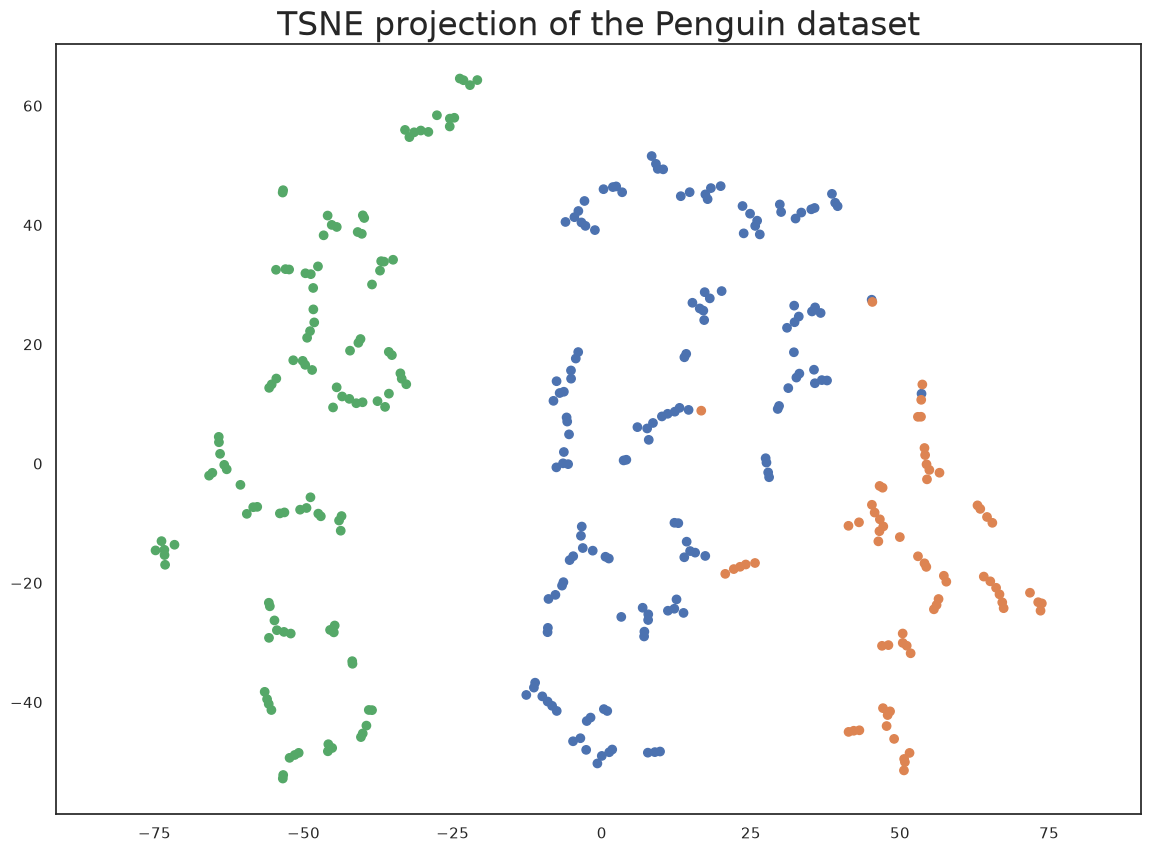

In [ ]:
plt.scatter(
    X_embedded[:, 0],
    X_embedded[:, 1],
    c=[sns.color_palette()[x] for x in penguins.species.map({"Adelie":0, "Chinstrap":1, "Gentoo":2})])
plt.gca().set_aspect('equal', 'datalim')
plt.title('TSNE projection of the Penguin dataset', fontsize=24);

In [ ]:
embedding = reducer.fit_transform(scaled_penguin_data)
embedding.shape 

pca = PCA(n_components=2, svd_solver='full')
X_pca = pca.fit_transform(scaled_penguin_data)

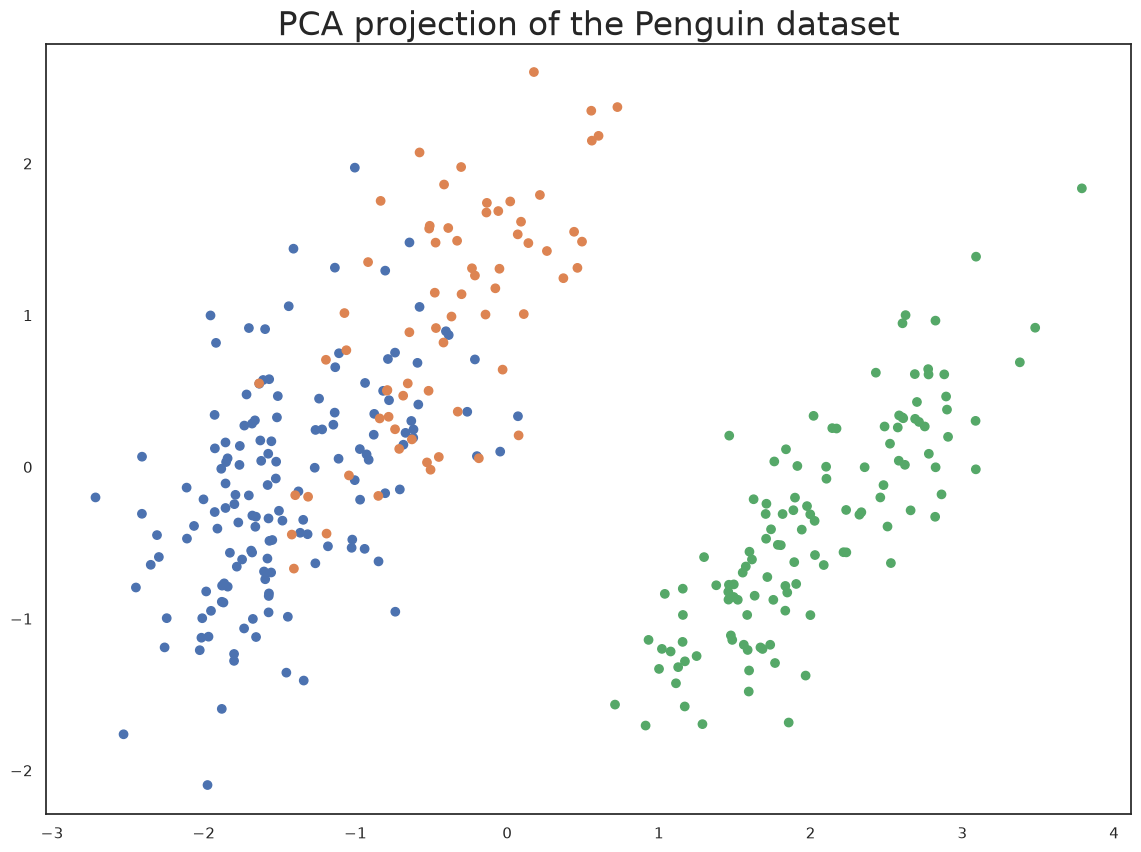

In [ ]:
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=[sns.color_palette()[x] for x in penguins.species.map({"Adelie":0, "Chinstrap":1, "Gentoo":2})])
plt.gca().set_aspect('equal', 'datalim')
plt.title('PCA projection of the Penguin dataset', fontsize=24);

c. Analyze the resulting plots and describe the main patterns you observe.

- Which method produces the most visually separable clusters?
- Are there any species that overlap in one method but not in others?
- What might explain these differences in how the data is projected?

Elaborate on your observations and compare the strengths and limitations of each method based on this toy example.


- UMAP produced the most visualluy serperated clusters. In the UMAP plot each species formed a tight and compact group and there is a lot of empty space around Gentoo. Also, in the t-SNE shows three clear groups but its clusters are looser and more spread out. UMAP has the highest silhoutte score which measures how compact and far apart the clusters are. I would say Gentoo is completely separated in all three methods since in the PCA they overlap a lot. The species averages and the PCA loadings explain most of it. Gentoo penguins are much bigger than the other two and have shallower bills, so they differ from the other two species in bill depth, flipper length and body mass only their bill length is close to.

d. For **t-SNE** and **UMAP**, explore how different hyperparameter settings affect the resulting 2D projections.

- For **t-SNE**, vary the `perplexity` parameter (e.g., 5, 30, 50).
- For **UMAP**, vary the `n_neighbors` parameter (e.g., 5, 15, 50) and optionally `min_dist`.
- Keep `random_state` fixed across all runs so that differences between projections are due primarily to changes in the hyperparameters rather than random initialization.

For each configuration:
- Plot the resulting 2D projection.
- Use color to represent species.

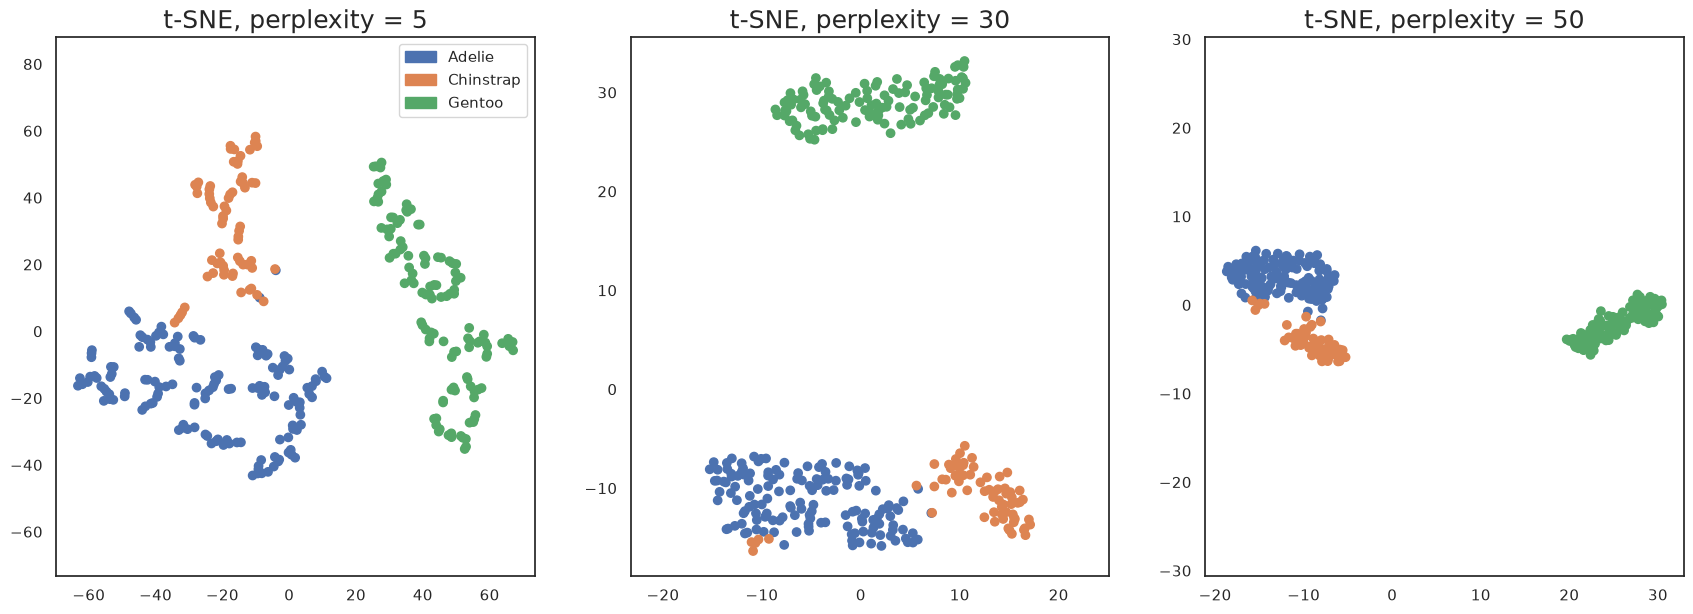

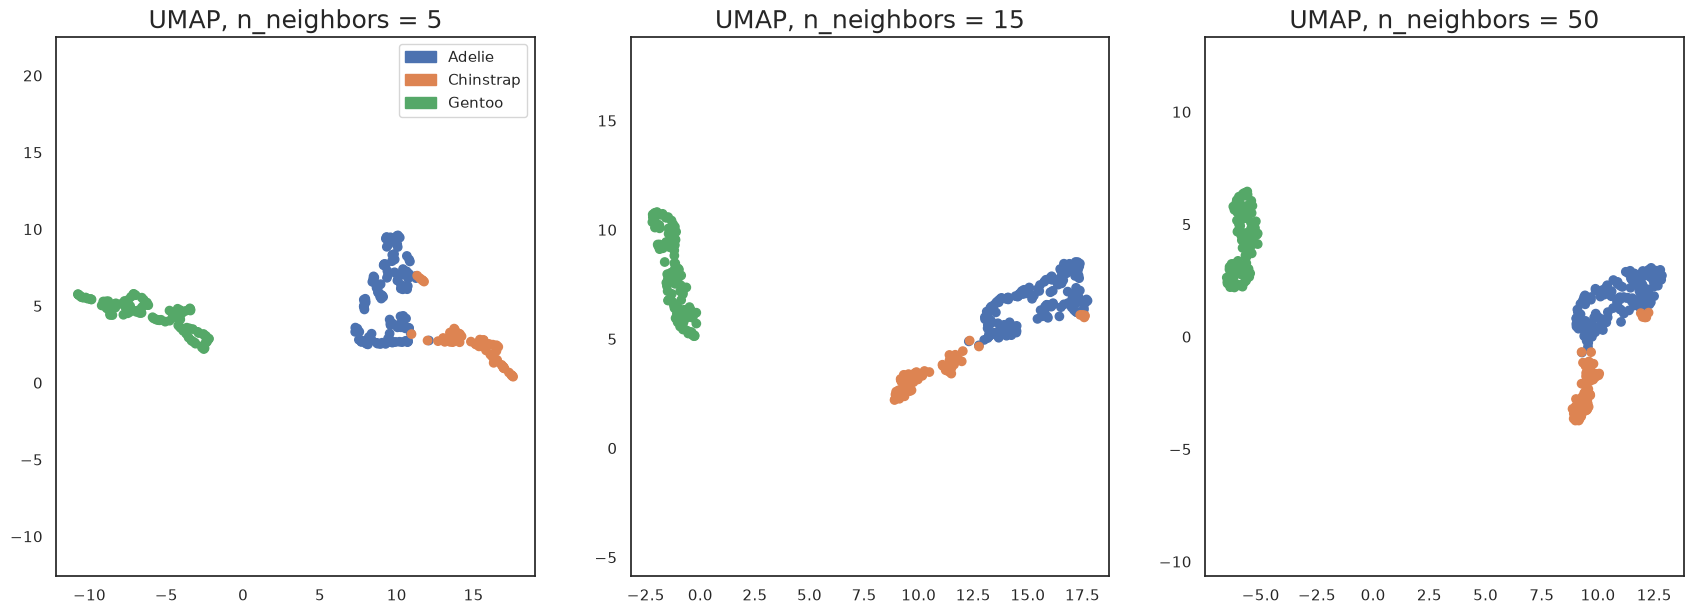

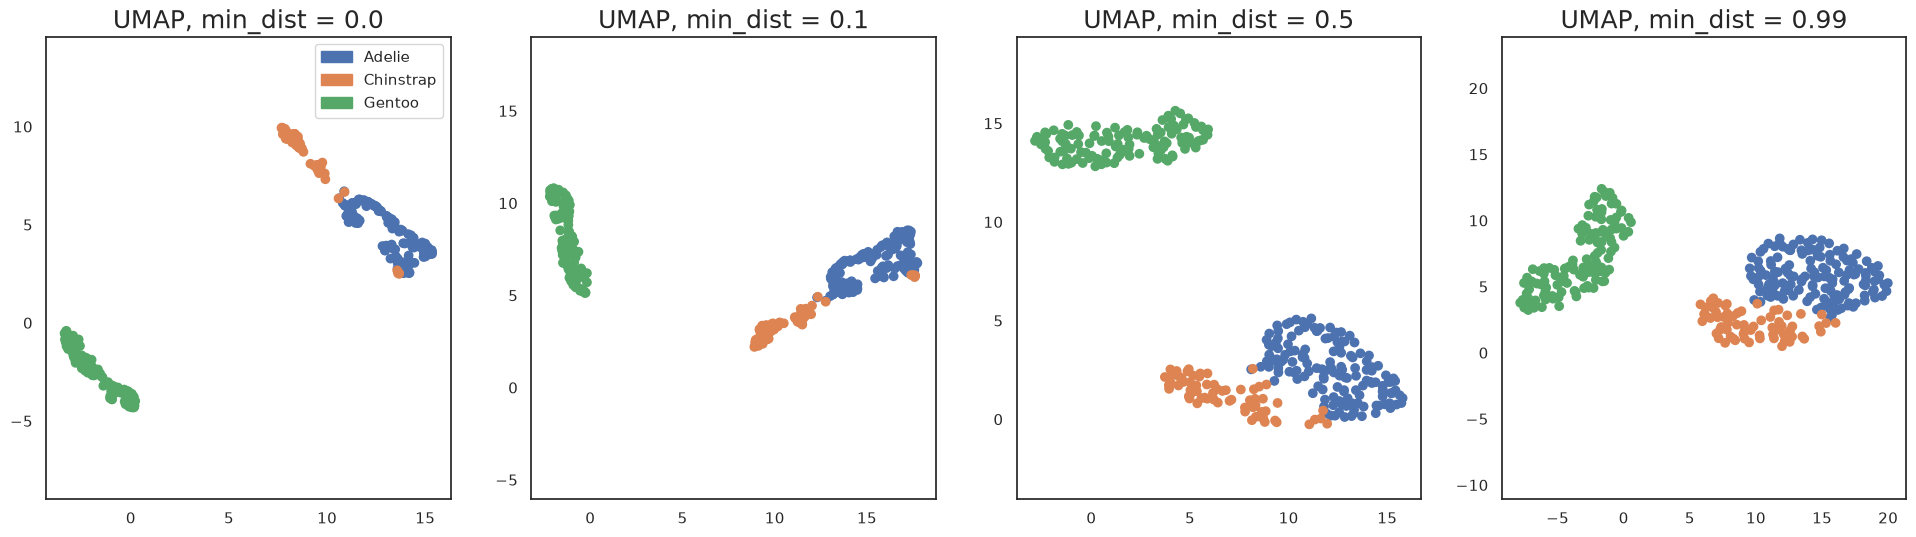

In [31]:
# YOUR CODE HERE

RANDOM_STATE = 42

# same species coloring we used in 2b, plus a legend
species_colors = [sns.color_palette()[x] for x in penguins.species.map({"Adelie": 0, "Chinstrap": 1, "Gentoo": 2})]
legend_handles = [Patch(color=sns.color_palette()[i], label=name)
                  for i, name in enumerate(["Adelie", "Chinstrap", "Gentoo"])]

# t-SNE: vary perplexity
perplexities = [5, 30, 50]
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, p in zip(axes, perplexities):
    X_tsne = TSNE(n_components=2, learning_rate='auto', init='random',
                  perplexity=p, random_state=RANDOM_STATE).fit_transform(scaled_penguin_data)
    ax.scatter(X_tsne[:, 0], X_tsne[:, 1], c=species_colors)
    ax.set_aspect('equal', 'datalim')
    ax.set_title(f't-SNE, perplexity = {p}', fontsize=18)
axes[0].legend(handles=legend_handles)
plt.show()

# UMAP: vary n_neighbors (min_dist stays at the default 0.1)
n_neighbors_list = [5, 15, 50]
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, n in zip(axes, n_neighbors_list):
    X_umap = umap.UMAP(n_neighbors=n, min_dist=0.1,
                       random_state=RANDOM_STATE).fit_transform(scaled_penguin_data)
    ax.scatter(X_umap[:, 0], X_umap[:, 1], c=species_colors)
    ax.set_aspect('equal', 'datalim')
    ax.set_title(f'UMAP, n_neighbors = {n}', fontsize=18)
axes[0].legend(handles=legend_handles)
plt.show()

# UMAP: vary min_dist (n_neighbors stays at the default 15)
min_dists = [0.0, 0.1, 0.5, 0.99]
fig, axes = plt.subplots(1, 4, figsize=(24, 6))
for ax, d in zip(axes, min_dists):
    X_umap = umap.UMAP(n_neighbors=15, min_dist=d,
                       random_state=RANDOM_STATE).fit_transform(scaled_penguin_data)
    ax.scatter(X_umap[:, 0], X_umap[:, 1], c=species_colors)
    ax.set_aspect('equal', 'datalim')
    ax.set_title(f'UMAP, min_dist = {d}', fontsize=18)
axes[0].legend(handles=legend_handles)
plt.show()

After generating the plots, describe the main changes you observe in the visualizations:
- How do the clusters shift, stretch, or separate as hyperparameters change?
- Which settings appear to better preserve the structure of the data?

Elaborate on your observations and support your discussion with specific visual examples.

As we increased perplexity for t-SNE and n_neighbors for UMAP, the clusters went from being broken up into lots of small pieces to forming smoother and more compact groups. With perplexity 5 and n_neighbors 5, each species was split into small chains and curls (Gentoo even looked like a long snake in UMAP), which makes it look like there are subgroups that are not really there. With perplexity 30 to 50 and n_neighbors 15 to 50, Gentoo formed its own cluster far away from the other two, while Adelie and Chinstrap stayed right next to each other with only a few Chinstraps mixed into the Adelie group. Changing min_dist mostly changed how tightly the points were packed, since min_dist = 0 squeezed each species into a thin line and min_dist = 0.99 spread them out into big, even clouds with smaller gaps between them. Overall, perplexity 30 to 50 and n_neighbors 15 to 50 with the default min_dist of 0.1 preserved the structure of the data best, because they show Gentoo as clearly different and Adelie and Chinstrap as similar, which matches what we saw in the PCA plot.

## 3. Apply to Real Data (1000 Genomes Subset) (25 points)

Your goal in this section is to try to create a figure similar to Figure 1 of the Diaz-Papkovich *et al.* (2019) paper, using a subset of genotype data from the 1000 Genomes Project.

To do so, complete the following steps:

a. Load the genotype dataset accompanying this lab, where each row corresponds to an individual, and each column to a genetic variant. Load also the provided population labels for each individual. 

b. **Standardize** the features (i.e., transform the genotype values to have zero mean and unit variance).

c. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the data to 2 dimensions. You may use the default values for the rest of hyperparameters in these techniques. 

d. Create **scatter plots** of the resulting projections, coloring each point according to its **population group**.

e. Reflect on the following questions:
- Explain what you observe in each case. Additionally, which method appears to provide the best visual separation of the population into distinct groups? Elaborate on why this might be the case, based on what you know about each method.
- What changes if you first reduce the data to the **top 25 PCA components**, and then apply t-SNE or UMAP?
- In your opinion, what are the trade-offs between **interpretability** (e.g., preservation of local and global structure) and **performance** (e.g., visual separation of known populations and computational time) when using these dimensionality reduction methods?

Please elaborate on your answers and use the plots to support your discussion.

In [ ]:
# YOUR CODE HERE

## 4. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE